A shuttling model of two sites, with two valleys per site, can be written as:
$$
H = \left(\begin{matrix}
    \varepsilon/2 + |\Delta_L| & 0 & t_{ee} & t_{eg} \\
    0 & \varepsilon/2-|\Delta_L| & t_{ge} & t_{gg} \\
    t_{ee}^* & t_{ge}^* & -(\varepsilon/2) + |\Delta_R| & 0 \\
    t_{eg}^* & t_{gg}^* & 0 & -(\varepsilon/2) - |\Delta_R| 
\end{matrix}\right),
$$
where $\varepsilon$ is the driving parameter, $\Delta_{L,R}$ are the intervalley coupling, and the tunneling rates read
$$
\begin{align}
    t_{ee}&=t_{gg}^*=\frac{t_c}{2}\left(1+e^{i(\phi_L-\phi_R)}\right),\\
    t_{eg}&=-t_{ge}^*=\frac{t_c}{2}\left(e^{i\phi_L}-e^{i\phi_R}\right).
\end{align}
$$

This notebook reproduces Fig. 11. We obtain the band structure of this system, and the pulses for an adiabatic transfer following the first excited state. The initial and target states are the first excited eigenstates of the Hamiltonian at $\varepsilon(t=0)=-10\,t_c$ and $\varepsilon(t=t_\mathrm{f})=10\,t_c$, respectively, i.e., the electron is moved from the left to the right dot in the excited valley state, $|L, v_L^+\rangle\mapsto|R, v_R^+\rangle$.

We compare the results for a pure system with those obtained with a Lindblad master equation $\dot{\rho}=-i[H,\rho]+\mathcal{D}[\rho]$, with the dissipator $\mathcal{D}[\rho]=\gamma\sum_i(\lambda_i\rho\lambda_i-\rho\lambda_i^2/2-\lambda_i^2\rho/2)$, where $\lambda_i$ are the three diagonal generalized Gell-Mann matrices (normalized as $\mathrm{Tr}[\lambda_i\lambda_j]=2\delta_{ij}$). This dissipator equals $\mathcal{D}[\rho]=2\gamma(\text{diag}(\rho)-\rho)$, i.e., all coherences decay with the rate $1/T_2=2\gamma$.

The red crosses denote the coordinates $(\alpha,\beta)$ with the minimum infidelity. The FAQUAD $(4,2)$ and the geometric fast-QUAD $(2,2)$ fidelities are printed for comparison.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import colorstamps

from HQUAD_lib.parallel_utils import parameter_run
from HQUAD_lib.QUAD_utils import compute_x_quad
from HQUAD_lib.hamiltonians import two_valleys_system
from HQUAD_lib.physics_utils import fidelity_shuttling

# Band structure

In [ ]:
tc = 1
phiL = 0 * np.pi
phiR = 0.8 * np.pi
DeltaL = 1
DeltaR = 2

eps_s = np.linspace(-10, 10, 2**18 + 1)  # 2 ** 20 + 1 points in the manuscript

partial_hamiltonian = np.array(
    [two_valleys_system(1, 0, 0, 0, 0, 0) for _ in range(len(eps_s))]
)

hypermatrix = np.array(
    [two_valleys_system(eps, tc, phiL, phiR, DeltaL, DeltaR) for eps in eps_s]
)
eigvalues, eigmodes = np.linalg.eigh(hypermatrix)

# Pulses

In [ ]:
alphas = np.linspace(
    -5, 5, 11
)  # Increase sample rate to enhance resolution (101 values in the manuscript)
betas = alphas

limit_sup = 1e8
n_s = 2**12 + 1  # Number of time steps for the pulse

result = parameter_run(
    compute_x_quad,
    [["alpha"], ["beta"]],
    [[alphas], [betas]],
    energies=eigvalues,
    states=eigmodes,
    x_vec=eps_s,
    partial_hamiltonian=partial_hamiltonian,
    adiabatic_state=1,
    limit_sup=limit_sup,
    n_s=n_s,
)

s = result[0][0]
eps_sol = result[1].reshape((len(alphas), len(betas), len(s)))

compute_x_quad: [['alpha'], ['beta']]:   0%|          | 0/121 [00:00<?, ?it/s]

In [ ]:
def compute_fidelity(pulse: np.ndarray, tf: float, gamma: float = 0) -> float:
    # Pulses that do not reach the final value of the detuning are discarded
    if pulse[-1] > eps_s[-1] + 0.5:
        return np.nan

    return fidelity_shuttling(
        pulse, tf, tc, phiL, phiR, DeltaL, DeltaR, gamma=gamma, adiabatic_state=1
    )

# No dephasing

In [ ]:
n_tf = 10  # Increase to get better results (200 values in the manuscript)
tf_list = np.linspace(0.1, 100, n_tf)

fidelitites_pure = parameter_run(
    compute_fidelity, [["pulse"], ["tf"]], [[eps_sol.reshape((-1, len(s)))], [tf_list]]
)

fidelitites_pure = fidelitites_pure.reshape((len(alphas), len(betas), n_tf))

compute_fidelity: [['pulse'], ['tf']]:   0%|          | 0/1210 [00:00<?, ?it/s]

# Dephasing

In [ ]:
gamma = 0.01
fidelities_dephasing = parameter_run(
    compute_fidelity,
    [["pulse"], ["tf"]],
    [[eps_sol.reshape((-1, len(s)))], [tf_list]],
    gamma=gamma,
)

fidelities_dephasing = fidelities_dephasing.reshape((len(alphas), len(betas), n_tf))
fidelities_dephasing[np.isnan(fidelities_dephasing)] = 0

compute_fidelity: [['pulse'], ['tf']]:   0%|          | 0/1210 [00:00<?, ?it/s]

# Plots

In [ ]:
def plot_fidelity(axs, fidelities, tf_list, alphas, betas, clabel=True):
    cmap_fidelity = mpl.colormaps["viridis_r"].copy()
    cmap_times = mpl.colormaps["inferno_r"].copy()

    cmap_fidelity.set_bad("white")
    cmap_times.set_bad("white")

    fidelities = np.nan_to_num(fidelities, nan=0)  # Discarded pulses are shown in white

    max_fidelity = np.max(fidelities[..., :], axis=2)
    tf_tilde = tf_list[np.argmax(fidelities[..., :], axis=2)]

    data_fidelity = np.log10(1 - max_fidelity)
    data_fidelity[max_fidelity == 0] = np.nan
    data_tf = tf_tilde
    data_tf[max_fidelity == 0] = np.nan

    vmax_F = np.nanmax(data_fidelity)
    vmin_F = np.nanmin(data_fidelity)

    vmax_tf = np.nanmax(data_tf)
    vmin_tf = np.nanmin(data_tf)

    im0 = axs[0].contourf(
        alphas,
        betas,
        data_fidelity.T,
        levels=15,
        vmin=vmin_F,
        vmax=vmax_F,
        cmap=cmap_fidelity,
    )
    im1 = axs[1].contourf(
        alphas, betas, data_tf.T, levels=15, vmin=vmin_tf, vmax=vmax_tf, cmap=cmap_times
    )

    if clabel:
        label0 = r"$\log_{10}(1 - \tilde{\mathcal{F}})$"
        label1 = r"$\tilde{t}_f\; [1 / t_c]$"
    else:
        label0 = None
        label1 = None

    cbar0 = plt.colorbar(im0, ax=axs[0], label=label0, location="top")
    cbar1 = plt.colorbar(im1, ax=axs[1], label=label1, location="top")

    cbar0.ax.set_xticks(cbar0.ax.get_xticks()[::3])
    cbar1.ax.set_xticks(cbar1.ax.get_xticks()[::2])

    cbars = [cbar0, cbar1]
    for cbar in cbars:
        if cbar.solids is not None:
            cbar.solids.set_edgecolor("face")

    for ax in axs:
        ax.set_xlabel(r"$\alpha$")

    axs[0].set_ylabel(r"$\beta$")

Coherent evolution:
    Best: 1 - F = 6.05e-06 at (alpha, beta) = (2.00, 1.00)
    FAQUAD: 1 - F = 2.23e-03
    Geometric: 1 - F = 4.00e-05
Dephasing evolution:
    Best: 1 - F = 1.59e-01 at (alpha, beta) = (4.00, 5.00)
    FAQUAD: 1 - F = 2.23e-01
    Geometric: 1 - F = 1.79e-01


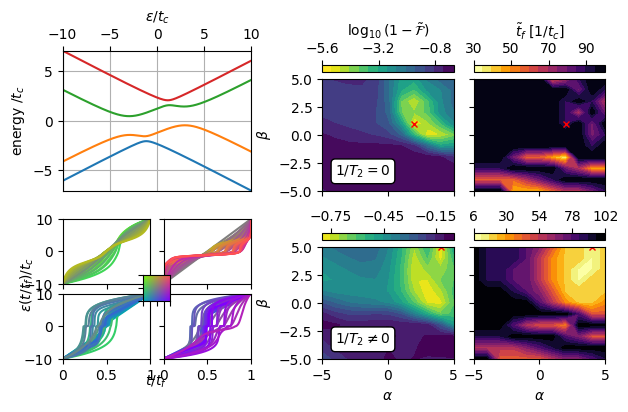

In [ ]:
fig = plt.figure(figsize=(7, 4))
gs0 = fig.add_gridspec(1, 2, wspace=0.3, width_ratios=[1, 1.5])

# Band structure
gs00 = gs0[0].subgridspec(2, 1)
axBand = fig.add_subplot(gs00[0])

axBand.plot(eps_s, eigvalues)
axBand.grid()
axBand.set_xlim(min(eps_s), max(eps_s))
axBand.set_ylim(np.min(eigvalues), np.max(eigvalues))

axBand.set_xlabel(r"$\varepsilon / t_c$")
axBand.set_ylabel(r"energy $/t_c$")
axBand.xaxis.tick_top()
axBand.xaxis.set_label_position("top")

# Fidelity w/o dephasing
gsFidelities = gs0[1].subgridspec(2, 2, wspace=0.15)

axsFidelity = []
for i in range(2):
    for j in range(2):
        axsFidelity.append(fig.add_subplot(gsFidelities[i, j]))
axsFidelity = np.array(axsFidelity).reshape((2, 2))

plot_fidelity(axsFidelity[0], fidelitites_pure, tf_list, alphas, betas)
for ax in axsFidelity[0]:
    ax.set_xticklabels([])
    ax.set_xlabel(None)
axsFidelity[0, 1].set_yticklabels([])

# Fidelity w/ dephasing
plot_fidelity(
    axsFidelity[1], fidelities_dephasing, tf_list, alphas, betas, clabel=False
)
axsFidelity[1, 1].set_yticklabels([])

# Best coordinates, FAQUAD and geometric fast-QUAD
index_FAQUAD = (np.argmin(np.abs(alphas - 4)), np.argmin(np.abs(betas - 2)))
index_geometric = (np.argmin(np.abs(alphas - 2)), np.argmin(np.abs(betas - 2)))

for row, (fidelities, title) in enumerate(
    zip([fidelitites_pure, fidelities_dephasing], ["Coherent", "Dephasing"])
):
    max_fidelity = np.max(np.nan_to_num(fidelities, nan=0), axis=2)
    best_indices = np.where(max_fidelity == np.max(max_fidelity))

    for ax in axsFidelity[row]:
        ax.plot(alphas[best_indices[0]], betas[best_indices[1]], "rx", markersize=5)

    print(f"{title} evolution:")
    print(
        f"    Best: 1 - F = {1 - np.max(max_fidelity):.2e} at (alpha, beta) = "
        f"({alphas[best_indices[0]][0]:.2f}, {betas[best_indices[1]][0]:.2f})"
    )
    print(f"    FAQUAD: 1 - F = {1 - max_fidelity[index_FAQUAD]:.2e}")
    print(f"    Geometric: 1 - F = {1 - max_fidelity[index_geometric]:.2e}")

axsFidelity[0, 0].text(
    0.1,
    0.1,
    r"$1 / T_2 = 0$",
    ha="left",
    transform=axsFidelity[0, 0].transAxes,
    va="bottom",
    bbox=dict(boxstyle="round", ec="k", fc="w", alpha=1),
)

axsFidelity[1, 0].text(
    0.1,
    0.1,
    r"$1 / T_2 \neq 0$",
    ha="left",
    transform=axsFidelity[1, 0].transAxes,
    va="bottom",
    bbox=dict(boxstyle="round", ec="k", fc="w", alpha=1),
)

# Pulses
gsPulses = gs00[1].subgridspec(2, 2, wspace=0.15, hspace=0.15)
axsPulses = []
for i in range(2):
    for j in range(2):
        axsPulses.append(fig.add_subplot(gsPulses[i, j]))
axsPulses = np.array(axsPulses).reshape((2, 2))

rgb, stamp = colorstamps.apply_stamp(*np.meshgrid(betas, alphas), "teuling0f")

lines = []
for i in range(len(alphas)):
    for j in range(len(betas)):
        if alphas[i] >= 0:
            column = 1
        else:
            column = 0

        if betas[j] >= 0:
            row = 0
        else:
            row = 1

        axsPulses[row, column].plot(s, eps_sol[i, j], c=rgb[i, j])

for ax in axsPulses.flatten():
    ax.set_xlim(0, 1)
    ax.set_ylim(-10, 10)

for ax in axsPulses[-1]:
    ax.set_xticks([0, 0.5, 1])
    ax.set_xticklabels(["0", "0.5", "1"])

axsPulses[1, 0].text(
    1.07, -0.4, r"$t / t_f$", ha="center", transform=axsPulses[1, 0].transAxes
)
axsPulses[1, 0].text(
    -0.5,
    1.15,
    r"$\varepsilon(t / t_f) /t_c$",
    va="center",
    rotation="vertical",
    transform=axsPulses[1, 0].transAxes,
)

for ax in axsPulses[:, 1]:
    ax.set_yticklabels([])

for ax in axsPulses[0]:
    ax.set_xticklabels([])

overlaid_ax = stamp.overlay_ax(
    axsPulses[1, 0], width=0.3, lower_left_corner=[0.88, 0.92]
)
overlaid_ax.set_xticklabels([])
overlaid_ax.set_yticklabels([]);